<a href="https://colab.research.google.com/github/loramarku9/BAZInaPODATOCI/blob/main/lan1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install datasets pandas

In [ ]:
from datasets import load_dataset

dataset = load_dataset("s-nlp/paradetox")

README.md:   0%|          | 0.00/7.59k [00:00<?, ?B/s]

train.tsv:   0%|          | 0.00/2.04M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/19744 [00:00<?, ? examples/s]

In [ ]:
print(dataset)
print(dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['en_toxic_comment', 'en_neutral_comment'],
        num_rows: 19744
    })
})
{'en_toxic_comment': 'he had steel balls too !', 'en_neutral_comment': 'he was brave too!'}


In [ ]:
import pandas as pd

df = dataset["train"].to_pandas()

df.head()

,en_toxic_comment,en_neutral_comment
0,he had steel balls too !,he was brave too!
1,"dude should have been taken to api , he would ...",It would have been good if he went to api. He ...
2,"im not gonna sell the fucking picture , i just...","I'm not gonna sell the picture, i just want to..."
3,the garbage that is being created by cnn and o...,the news that is being created by cnn and othe...
4,the reason they dont exist is because neither ...,The reason they don't exist is because neither...


In [ ]:
sentence = "I love machine learning"

words = sentence.split()

print(words)
print(len(words))

['I', 'love', 'machine', 'learning']
4


In [ ]:
df["toxic_word_count"] = df["en_toxic_comment"].apply(
    lambda sentence: len(sentence.split())
)

df.head()

,en_toxic_comment,en_neutral_comment,toxic_word_count
0,he had steel balls too !,he was brave too!,6
1,"dude should have been taken to api , he would ...",It would have been good if he went to api. He ...,20
2,"im not gonna sell the fucking picture , i just...","I'm not gonna sell the picture, i just want to...",18
3,the garbage that is being created by cnn and o...,the news that is being created by cnn and othe...,15
4,the reason they dont exist is because neither ...,The reason they don't exist is because neither...,15


In [ ]:
df["neutral_word_count"] = df["en_neutral_comment"].apply(
    lambda sentence:len(sentence.split())
)
df.head()

,en_toxic_comment,en_neutral_comment,toxic_word_count,neutral_word_count
0,he had steel balls too !,he was brave too!,6,4
1,"dude should have been taken to api , he would ...",It would have been good if he went to api. He ...,20,14
2,"im not gonna sell the fucking picture , i just...","I'm not gonna sell the picture, i just want to...",18,14
3,the garbage that is being created by cnn and o...,the news that is being created by cnn and othe...,15,14
4,the reason they dont exist is because neither ...,The reason they don't exist is because neither...,15,11


In [ ]:
avg_toxic = df["toxic_word_count"].mean();
avg_neutral = df["neutral_word_count"].mean();

print("Average toxic sentence length: ", avg_toxic)
print("Average toxic nautral length: ", avg_neutral)

Average toxic sentence length:  11.866339141004863
Average toxic nautral length:  9.317108995137763


In [ ]:
from collections import Counter
print("Step 1")

Step 1


In [ ]:
toxic_words=[]

for sentence in df["en_toxic_comment"]:
  words=sentence.lower().split();
  toxic_words.extend(words)

toxic_counts=Counter(toxic_words)

print(toxic_counts.most_common(10))


[('.', 10179), ('the', 6932), ('shit', 6157), (',', 5482), ('i', 5266), ('a', 4600), ('you', 4296), ('to', 4222), ('!', 3715), ('is', 3392)]


In [ ]:
neutral_words=[]

for sentence in df["en_neutral_comment"]:
  words=sentence.lower().split()
  neutral_words.extend(words)

neutral_counts=Counter(neutral_words)

print("TOXIC:", toxic_counts.most_common(10))
print("NEUTRAL:", neutral_counts.most_common(10))

TOXIC: [('.', 10179), ('the', 6932), ('shit', 6157), (',', 5482), ('i', 5266), ('a', 4600), ('you', 4296), ('to', 4222), ('!', 3715), ('is', 3392)]
NEUTRAL: [('the', 5188), ('i', 4944), ('to', 4181), ('you', 4012), ('is', 3612), ('a', 3328), ('that', 2700), ('and', 2632), ('.', 2238), ('this', 2203)]


In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 47.2 MB/s  0:00:00


In [ ]:
sentences = []

for sentence in df["en_toxic_comment"]:
    sentences.append(sentence.lower().split())

for sentence in df["en_neutral_comment"]:
    sentences.append(sentence.lower().split())

print(sentences[:3])
print("Total sentences:", len(sentences))

[['he', 'had', 'steel', 'balls', 'too', '!'], ['dude', 'should', 'have', 'been', 'taken', 'to', 'api', ',', 'he', 'would', 'be', 'right', 'at', 'home', 'with', 'all', 'the', 'other', 'knuckleheads', 'there'], ['im', 'not', 'gonna', 'sell', 'the', 'fucking', 'picture', ',', 'i', 'just', 'want', 'to', 'contribute', 'to', 'the', 'fucking', 'article', '.']]
Total sentences: 39488


In [ ]:
from gensim.models import Word2Vec

model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=3,
    min_count=1,
    sg=0
)

In [ ]:
print(model.wv["hello"][:10])

[ 0.02651195  0.05835572  0.01586916  0.03364303 -0.00992258 -0.08532254
 -0.02323131  0.19781193 -0.02745512 -0.05402881]


In [ ]:
toxic_top15 = [word for word, count in toxic_counts.most_common(15)]
neutral_top15 = [word for word, count in neutral_counts.most_common(15)]

print("Toxic words:", toxic_top15)
print("Neutral words:", neutral_top15)

Toxic words: ['.', 'the', 'shit', ',', 'i', 'a', 'you', 'to', '!', 'is', 'that', 'fuck', '?', 'and', 'fucking']
Neutral words: ['the', 'i', 'to', 'you', 'is', 'a', 'that', 'and', '.', 'this', 'of', 'it', 'are', 'not', 'in']


In [ ]:
import numpy as np
from sklearn.decomposition import PCA

all_words = toxic_top15 + neutral_top15

vectors = np.array([model.wv[word] for word in all_words])

pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(vectors)

print(vectors_2d.shape)

(30, 2)


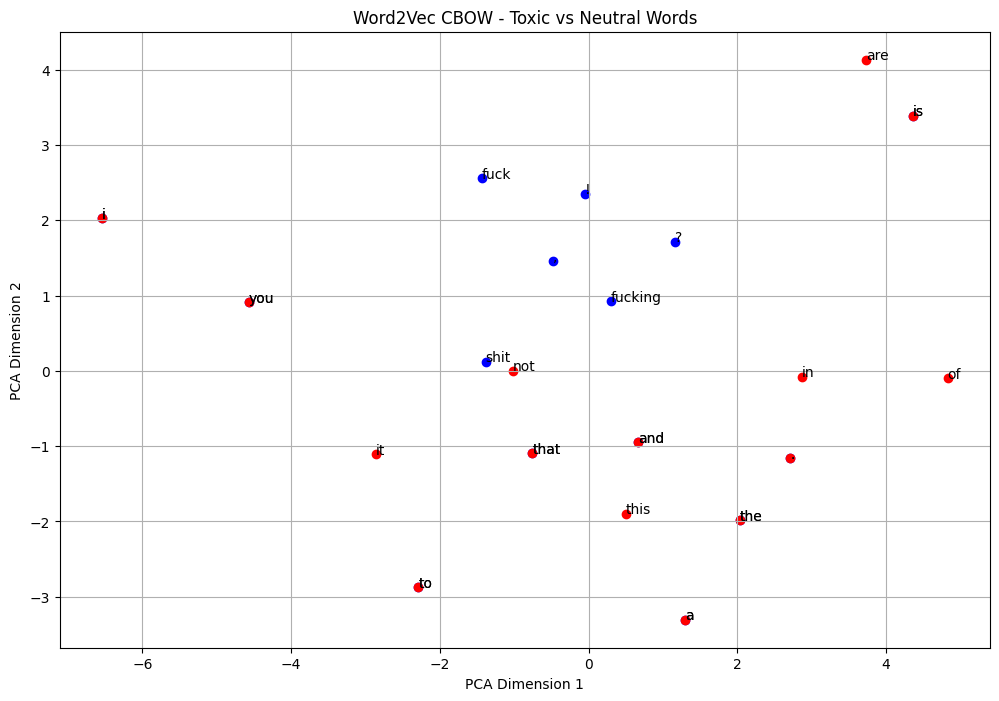

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i, word in enumerate(all_words):
    x = vectors_2d[i, 0]
    y = vectors_2d[i, 1]

    if i < 15:
        color = "blue"
    else:
        color = "red"

    plt.scatter(x, y, color=color)
    plt.annotate(word, (x, y))

plt.title("Word2Vec CBOW - Toxic vs Neutral Words")
plt.xlabel("PCA Dimension 1")
plt.ylabel("PCA Dimension 2")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np

word_vectors = np.array([
    [0.2, 0.8, -0.3],
    [0.5, 0.1, 0.6],
    [-0.1, 0.4, 0.9]
])

sentence_vector = np.max(word_vectors, axis=0)

print(sentence_vector)

[0.5 0.8 0.9]


In [ ]:
import numpy as np

def get_sentence_vector(sentence):
    words = sentence.lower().split()
    vectors = []

    for word in words:
        if word in model.wv:
            vectors.append(model.wv[word])

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.max(vectors, axis=0)


toxic_sentence_vectors = np.array([
    get_sentence_vector(sentence)
    for sentence in df["en_toxic_comment"]
])

neutral_sentence_vectors = np.array([
    get_sentence_vector(sentence)
    for sentence in df["en_neutral_comment"]
])

print("Toxic vectors:", toxic_sentence_vectors.shape)
print("Neutral vectors:", neutral_sentence_vectors.shape)

Toxic vectors: (19744, 100)
Neutral vectors: (19744, 100)


In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

toxic_df = pd.DataFrame({
    "text": df["en_toxic_comment"],
    "label": 1
})

neutral_df = pd.DataFrame({
    "text": df["en_neutral_comment"],
    "label": 0
})

classification_df = pd.concat(
    [toxic_df, neutral_df],
    ignore_index=True
)

train_df, temp_df = train_test_split(
    classification_df,
    test_size=0.10,
    random_state=42,
    stratify=classification_df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 35539
Validation: 1974
Testing: 1975


In [ ]:
!pip install -q transformers datasets accelerate scikit-learn

In [ ]:
import torch
import numpy as np

from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_dataset = Dataset.from_pandas(
    train_df.reset_index(drop=True),
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df.reset_index(drop=True),
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df.reset_index(drop=True),
    preserve_index=False
)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

model_bert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

print("Datasets prepared successfully!")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/35539 [00:00<?, ? examples/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Datasets prepared successfully!


In [ ]:
from transformers import (
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)

from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


training_args = TrainingArguments(
    output_dir="./bert_paradetox",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=1,
    report_to="none",
    fp16=torch.cuda.is_available()
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = Trainer(
    model=model_bert,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.081275,0.071638,0.973658,0.962413,0.985816,0.973974
2,0.046917,0.068046,0.978723,0.971087,0.986829,0.978894
3,0.038758,0.075430,0.979230,0.974900,0.983789,0.979324


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=6666, training_loss=0.062478443898848504, metrics={'train_runtime': 553.7406, 'train_samples_per_second': 192.54, 'train_steps_per_second': 12.038, 'total_flos': 1253720581568940.0, 'train_loss': 0.062478443898848504, 'epoch': 3.0})

In [32]:
test_results = trainer.evaluate(test_dataset)

print("FINAL TEST RESULTS")
print("Accuracy:", test_results["eval_accuracy"])
print("Precision:", test_results["eval_precision"])
print("Recall:", test_results["eval_recall"])
print("F1-score:", test_results["eval_f1"])
print("Test Loss:", test_results["eval_loss"])

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.038758,0.085103,3,0.977215,0.970060,0.984802,0.977376


FINAL TEST RESULTS
Accuracy: 0.9772151898734177
Precision: 0.9700598802395209
Recall: 0.9848024316109423
F1-score: 0.9773755656108597
Test Loss: 0.08510346710681915


CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Neutral       0.98      0.97      0.98       988
       Toxic       0.97      0.98      0.98       987

    accuracy                           0.98      1975
   macro avg       0.98      0.98      0.98      1975
weighted avg       0.98      0.98      0.98      1975



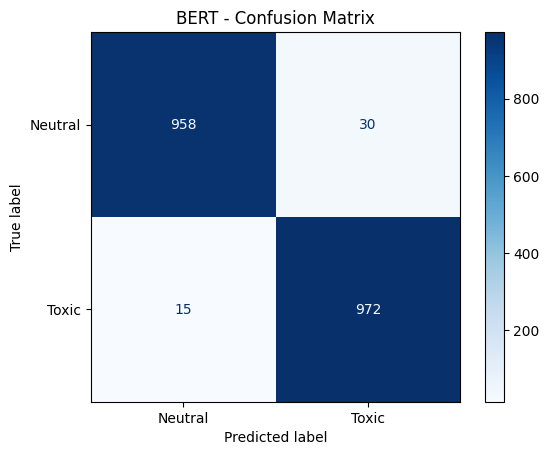

In [33]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

predictions_output = trainer.predict(test_dataset)

predicted_labels = np.argmax(
    predictions_output.predictions,
    axis=-1
)

true_labels = predictions_output.label_ids

print("CLASSIFICATION REPORT")
print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=["Neutral", "Toxic"],
        zero_division=0
    )
)

cm = confusion_matrix(true_labels, predicted_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Neutral", "Toxic"]
)

disp.plot(cmap="Blues")
plt.title("BERT - Confusion Matrix")
plt.show()